# Sales Performance Analysis

## Contexto del análisis

En este notebook analizamos el rendimiento comercial de COMPLEX SOLUTIONS S.L. para comprender cómo evolucionan las ventas y qué diferencias existen entre los canales comerciales y las categorías de producto.

El objetivo es identificar patrones de facturación, volumen de ventas y rentabilidad que ayuden a comprender el comportamiento comercial de la empresa y a detectar posibles oportunidades de mejora.

## Objetivos

- Analizar el rendimiento comercial por canal de venta.
- Comparar la contribución de las categorías de producto a los ingresos y al beneficio bruto.
- Examinar la evolución mensual de las ventas.
- Investigar la relación entre el número de operaciones, el volumen vendido y el ticket medio.
- Identificar patrones relevantes y formular conclusiones basadas en los datos.

## Preparación de los datos

Para realizar el análisis utilizaremos los datos de ventas y productos preparados durante el proyecto.

Antes de calcular las métricas, comprobaremos la disponibilidad de las columnas necesarias, la consistencia de los datos y el nivel de detalle de cada tabla.

Esta revisión permitirá seleccionar las fuentes adecuadas para cada análisis y evitar duplicidades en los cálculos.

In [361]:
import os
import pandas as pd
import numpy as np

from sqlalchemy import create_engine
from dotenv import load_dotenv

load_dotenv()

DB_NAME = os.getenv("POSTGRES_DB")
DB_USER = os.getenv("POSTGRES_USER")
DB_PASSWORD = os.getenv("POSTGRES_PASSWORD")
DB_HOST = "localhost"
DB_PORT = os.getenv("POSTGRES_PORT")

In [362]:
engine = create_engine(
    f"postgresql+psycopg://{DB_USER}:{DB_PASSWORD}@{DB_HOST}:{DB_PORT}/{DB_NAME}"
)

with engine.connect() as connection:
    result = connection.exec_driver_sql(
        "SELECT current_database(), current_user;"
    ).fetchone()

print("Conexión establecida correctamente.")
print("Base de datos:", result[0])
print("Usuario:", result[1])


Conexión establecida correctamente.
Base de datos: complex_solutions
Usuario: complex_admin


## Exploración de las tablas disponibles

Antes de comenzar el análisis del rendimiento comercial, identificamos las tablas disponibles en PostgreSQL para conocer las fuentes de datos que podemos utilizar.

Esta comprobación nos permitirá seleccionar las tablas adecuadas y verificar dónde se encuentran los datos de ventas, productos y categorías.

In [363]:
tables_query = """
SELECT table_name
FROM information_schema.tables
WHERE table_schema = 'public'
    AND table_type = 'BASE TABLE'
ORDER BY table_name;
"""

tables_df = pd.read_sql(tables_query, engine)

tables_df

,table_name
0,categories
1,crm_activities
2,customers
3,employees
4,inventory_movements
5,invoices
6,leads
7,opportunities
8,products
9,purchase_items


In [364]:
schema_query = """
SELECT
    table_name,
    column_name,
    data_type
FROM information_schema.columns
WHERE table_schema = 'public'
    AND table_name IN (
        'invoices',
        'products',
        'categories',
        'customers'
    )
ORDER BY table_name, ordinal_position;
"""

schema_df = pd.read_sql(schema_query, engine)

schema_df.to_string(index=False)

'table_name         column_name data_type\ncategories         category_id    bigint\ncategories       category_name      text\n customers         customer_id    bigint\n customers       customer_type      text\n customers        company_name      text\n customers    customer_segment      text\n customers                city      text\n customers            province      text\n customers         signup_date      date\n customers acquisition_channel      text\n customers        sales_rep_id    bigint\n  invoices          invoice_id    bigint\n  invoices             sale_id    bigint\n  invoices        invoice_date      date\n  invoices            due_date      date\n  invoices              status      text\n  invoices        total_amount   numeric\n  products          product_id    bigint\n  products                 sku      text\n  products        product_name      text\n  products         category_id    bigint\n  products               brand      text\n  products         supplier_id   

## Inspección de las tablas restantes

Para completar el reconocimiento de las fuentes de datos, examinaremos las columnas de las tablas restantes de la base de datos.

Prestaremos especial atención a las tablas relacionadas con las operaciones comerciales, los pedidos y los movimientos de inventario, con el objetivo de localizar el detalle necesario para analizar las ventas.

In [365]:
remaining_tables_query = """
SELECT
    table_name,
    column_name,
    data_type
FROM information_schema.columns
WHERE table_schema = 'public'
    AND table_name NOT IN (
        'categories',
        'customers',
        'invoices',
        'products'
    )
ORDER BY table_name, ordinal_position;
"""

remaining_schema_df = pd.read_sql(remaining_tables_query, engine)

print(remaining_schema_df.to_string(index=False))

         table_name         column_name data_type
     crm_activities         activity_id    bigint
     crm_activities      opportunity_id    bigint
     crm_activities         employee_id    bigint
     crm_activities       activity_type      text
     crm_activities       activity_date      date
          employees         employee_id    bigint
          employees                name      text
          employees          department      text
          employees                role      text
          employees           hire_date      date
inventory_movements         movement_id    bigint
inventory_movements          product_id    bigint
inventory_movements       movement_date      date
inventory_movements       movement_type      text
inventory_movements            quantity   integer
inventory_movements           unit_cost   numeric
              leads             lead_id    bigint
              leads        company_name      text
              leads        created_date      date


## Identificación de las fuentes de datos comerciales

Tras examinar la estructura de la base de datos, identificamos las tablas que contienen información relacionada con las operaciones comerciales.

En esta fase nos centraremos en las ventas, las oportunidades comerciales y las compras, para determinar qué fuentes necesitamos incorporar al análisis de rendimiento comercial.

In [366]:
tables_df["table_name"].to_list()

['categories',
 'crm_activities',
 'customers',
 'employees',
 'inventory_movements',
 'invoices',
 'leads',
 'opportunities',
 'products',
 'purchase_items',
 'purchase_orders',
 'sale_items',
 'sales',
 'suppliers']

## Estructura de las tablas de ventas

Una vez localizadas las tablas `sales` y `sale_items`, examinaremos sus columnas y tipos de datos.

La primera contiene previsiblemente información general de las operaciones comerciales, mientras que la segunda permitirá identificar el detalle de los productos vendidos.

Esta separación nos ayudará a comprender cómo se relacionan las ventas con sus productos y qué información podemos utilizar para calcular los indicadores comerciales.

In [367]:
sales_schema_query = """
SELECT
    table_name,
    column_name,
    data_type
FROM information_schema.columns
WHERE table_schema = 'public'
    AND table_name IN ('sales', 'sale_items')
ORDER BY table_name, ordinal_position;
"""

sales_schema_df = pd.read_sql(sales_schema_query, engine)

print(sales_schema_df.to_string(index=False))

table_name  column_name data_type
sale_items sale_item_id    bigint
sale_items      sale_id    bigint
sale_items   product_id    bigint
sale_items     quantity   integer
sale_items   unit_price   numeric
sale_items     discount   numeric
sale_items    unit_cost   numeric
     sales      sale_id    bigint
     sales  customer_id    bigint
     sales  employee_id    bigint
     sales    sale_date      date
     sales      channel      text
     sales       status      text


## Primera inspección de los registros comerciales

Una vez identificada la estructura de las tablas de ventas, examinaremos algunos registros reales para comprender cómo están almacenados los datos.

Esta comprobación permitirá conocer los valores utilizados en los canales de venta y estados de las operaciones, así como interpretar correctamente los precios, costes y descuentos aplicados.

In [368]:
sales_sample_df = pd.read_sql(
    "SELECT * FROM sales LIMIT 10;",
    engine
)

sale_items_sample_df = pd.read_sql(
    "SELECT * FROM sale_items LIMIT 10;",
    engine
)

display(sales_sample_df)
display(sale_items_sample_df)

,sale_id,customer_id,employee_id,sale_date,channel,status
0,1,177,1,2026-11-06,PHYSICAL_STORE,CONFIRMED
1,2,317,1,2024-06-12,ONLINE,CONFIRMED
2,3,55,1,2026-06-30,B2B,CONFIRMED
3,4,345,1,2025-06-10,ONLINE,CONFIRMED
4,5,166,1,2025-08-22,B2B,CONFIRMED
5,6,251,1,2021-12-09,PHYSICAL_STORE,CONFIRMED
6,7,171,1,2024-11-15,ONLINE,CONFIRMED
7,8,269,1,2023-08-19,PHYSICAL_STORE,CONFIRMED
8,9,273,1,2023-02-28,ONLINE,CONFIRMED
9,10,307,1,2024-01-27,B2B,CONFIRMED


,sale_item_id,sale_id,product_id,quantity,unit_price,discount,unit_cost
0,1,1,8,2,458.70,0.0534,462.04
1,2,2,3,2,68.97,0.0518,61.10
2,3,3,12,2,1310.76,0.2107,1100.24
3,4,4,118,2,309.38,0.0386,245.25
4,5,5,28,3,1419.99,0.2015,1082.37
5,6,6,11,3,1043.62,0.0441,839.85
6,7,7,65,2,28.88,0.0351,26.80
7,8,8,38,3,272.25,0.0456,237.15
8,9,9,88,1,527.50,0.0777,439.52
9,10,10,23,2,361.51,0.1520,335.54


## Validación de los valores comerciales

Antes de realizar los cálculos, comprobaremos los valores existentes en los canales de venta y los estados de las operaciones.

También examinaremos la distribución de los descuentos para conocer su rango y confirmar cómo están representados en la base de datos.

Esta validación permitirá establecer criterios adecuados para los posteriores cálculos de rendimiento comercial.

In [369]:
# Valores existentes en los canales de venta
channels_df = pd.read_sql("""
    SELECT channel, COUNT(*) AS total_sales
    FROM sales
    GROUP BY channel
    ORDER BY total_sales DESC;
""", engine)

# Valores existentes en los estados de las ventas
statuses_df = pd.read_sql("""
    SELECT status, COUNT(*) AS total_sales
    FROM sales
    GROUP BY status
    ORDER BY total_sales DESC;
""", engine)

# Distribución de los descuentos
discount_stats_df = pd.read_sql("""
    SELECT
        MIN(discount) AS min_discount,
        MAX(discount) AS max_discount,
        AVG(discount) AS avg_discount,
        COUNT(*) AS total_lines
    FROM sale_items;
""", engine)

display(channels_df)
display(statuses_df)
display(discount_stats_df)

,channel,total_sales
0,ONLINE,937
1,B2B,683
2,PHYSICAL_STORE,481


,status,total_sales
0,CONFIRMED,2101


,min_discount,max_discount,avg_discount,total_lines
0,0.0,0.2199,0.088713,2101


## Validación temporal y granularidad de las ventas

Antes de comenzar el análisis comercial, comprobaremos el intervalo temporal de las operaciones y la relación entre las ventas y sus líneas de detalle.

Esta revisión permitirá identificar posibles registros con fechas futuras y conocer cuántas líneas de producto contiene cada operación comercial.

In [370]:
sales_validation_query = """
SELECT
    MIN(s.sale_date) AS first_sale_date,
    MAX(s.sale_date) AS last_sale_date,
    COUNT(*) FILTER (
        WHERE s.sale_date > CURRENT_DATE
    ) AS future_sales,
    COUNT(DISTINCT s.sale_id) AS total_sales,
    COUNT(DISTINCT si.sale_item_id) AS total_sale_items,
    COUNT(DISTINCT si.sale_id) AS sales_with_items,
    COUNT(*) AS total_joined_rows
FROM sales s
LEFT JOIN sale_items si
    ON s.sale_id = si.sale_id;
"""

sales_validation_df = pd.read_sql(
    sales_validation_query,
    engine
)

sales_validation_df

,first_sale_date,last_sale_date,future_sales,total_sales,total_sale_items,sales_with_items,total_joined_rows
0,2020-01-15,2026-12-20,82,2101,2101,2101,2101


## Análisis de la estructura de las operaciones comerciales

Los primeros resultados muestran que el número de ventas coincide con el número de líneas de venta.

Para confirmar esta relación, analizaremos cuántas líneas de producto contiene cada operación y comprobaremos la distribución de las ventas con fechas posteriores al 30 de octubre de 2026.

Esta revisión permitirá conocer la granularidad real de los registros y establecer el tratamiento adecuado de las operaciones futuras.

In [371]:
# Número de líneas de producto por venta
sale_items_distribution_df = pd.read_sql("""
    SELECT
        items_per_sale,
        COUNT(*) AS total_sales
    FROM (
        SELECT
            sale_id,
            COUNT(*) AS items_per_sale
        FROM sale_items
        GROUP BY sale_id
    ) AS sales_detail
    GROUP BY items_per_sale
    ORDER BY items_per_sale;
""", engine)


# Distribución mensual de las ventas futuras
future_sales_df = pd.read_sql("""
    SELECT
        DATE_TRUNC('month', sale_date)::date AS month,
        COUNT(*) AS total_sales
    FROM sales
    WHERE sale_date > DATE '2026-10-30'
    GROUP BY DATE_TRUNC('month', sale_date)
    ORDER BY month;
""", engine)

display(sale_items_distribution_df)
display(future_sales_df)

,items_per_sale,total_sales
0,1,2101


,month,total_sales
0,2026-11-01,51
1,2026-12-01,35


## Conclusiones de la exploración de datos

La exploración inicial ha permitido identificar las principales fuentes de información necesarias para analizar el rendimiento comercial de COMPLEX SOLUTIONS S.L.

El conjunto de datos contiene información histórica desde enero de 2020 hasta diciembre de 2026 y recoge 2.101 operaciones comerciales distribuidas entre tres canales: ONLINE, B2B y PHYSICAL_STORE.

Todas las operaciones registradas presentan el estado CONFIRMED. Además, se ha comprobado que cada venta contiene una única línea de producto.

Los descuentos están representados mediante valores decimales y oscilan entre el 0 % y el 21,99 %.

Con esta información, disponemos de una primera visión de la estructura comercial y podemos comenzar la preparación de los datos que utilizaremos para analizar las ventas por canal, categoría y evolución temporal.

## Preparación del dataset de análisis comercial

Para realizar el análisis del rendimiento comercial, combinaremos la información de las distintas tablas de PostgreSQL en un único conjunto de datos.

Integraremos las operaciones de venta con el detalle de los productos, sus categorías y la información de los clientes.

También calcularemos el precio efectivo después del descuento, los ingresos generados, el coste total y el beneficio bruto de cada operación.

El resultado será una tabla centralizada que utilizaremos como fuente para los posteriores análisis de ventas por canal, categoría y evolución temporal.

In [372]:
sales_analysis_query = """
SELECT
    s.sale_id,
    s.sale_date,
    s.channel,
    s.status,
    s.customer_id,
    c.customer_type,
    c.customer_segment,

    si.sale_item_id,
    si.product_id,
    p.product_name,
    p.category_id,
    cat.category_name,

    si.quantity,
    si.unit_price,
    si.discount,
    si.unit_price * (1 - si.discount) AS effective_unit_price,
    si.unit_cost,

    si.quantity * si.unit_price * (1 - si.discount) AS revenue,
    si.quantity * si.unit_cost AS total_cost,

    si.quantity * (
        si.unit_price * (1 - si.discount) - si.unit_cost
    ) AS gross_profit

FROM sales s

INNER JOIN sale_items si
    ON s.sale_id = si.sale_id

INNER JOIN products p
    ON si.product_id = p.product_id

INNER JOIN categories cat
    ON p.category_id = cat.category_id

INNER JOIN customers c
    ON s.customer_id = c.customer_id

ORDER BY s.sale_date;
"""

sales_analysis_df = pd.read_sql(sales_analysis_query, engine)

sales_analysis_df.head()

,sale_id,sale_date,channel,status,customer_id,customer_type,customer_segment,sale_item_id,product_id,product_name,category_id,category_name,quantity,unit_price,discount,effective_unit_price,unit_cost,revenue,total_cost,gross_profit
0,1619,2020-01-15,B2B,CONFIRMED,145,B2B,SMB,1619,1,Acer Computers Model 1,1,Computers,2,27.50,0.1967,22.090750,25.0,44.181500,50.0,-5.818500
1,456,2020-03-01,B2B,CONFIRMED,133,B2B,SMB,456,12,ASUS Components Model 12,2,Components,2,1310.76,0.2125,1032.223500,993.0,2064.447000,1986.0,78.447000
2,1163,2020-03-15,ONLINE,CONFIRMED,81,B2C,CONSUMER,1163,10,Western Digital Security Model 10,10,Security,2,814.33,0.0714,756.186838,673.0,1512.373676,1346.0,166.373676
3,625,2020-03-20,ONLINE,CONFIRMED,336,B2C,CONSUMER,625,9,TP-Link Servers Model 9,9,Servers,1,620.24,0.0732,574.838432,537.0,574.838432,537.0,37.838432
4,1419,2020-03-23,B2B,CONFIRMED,133,B2B,SMB,1419,9,TP-Link Servers Model 9,9,Servers,2,620.24,0.1019,557.037544,537.0,1114.075088,1074.0,40.075088


## Validación del dataset comercial

Una vez construido el conjunto de datos unificado, comprobaremos su estructura y calidad.

Revisaremos el número de registros y columnas, la presencia de valores nulos y posibles duplicidades en los identificadores de venta.

Esta validación permitirá comprobar que la integración de las distintas tablas se ha realizado correctamente antes de comenzar el análisis comercial.

In [373]:
# Dimensiones del DataFrame
print("Dimensiones del dataset:", sales_analysis_df.shape)

# Número de ventas y líneas distintas
print("Ventas únicas:", sales_analysis_df["sale_id"].nunique())
print("Líneas de venta únicas:", sales_analysis_df["sale_item_id"].nunique())

# Valores nulos por columna
print("\nValores nulos:")
print(sales_analysis_df.isna().sum().to_string())

# Identificadores de venta duplicados
print(
    "\nVentas duplicadas:",
    sales_analysis_df["sale_id"].duplicated().sum()
)

Dimensiones del dataset: (2101, 20)
Ventas únicas: 2101
Líneas de venta únicas: 2101

Valores nulos:
sale_id                 0
sale_date               0
channel                 0
status                  0
customer_id             0
customer_type           0
customer_segment        0
sale_item_id            0
product_id              0
product_name            0
category_id             0
category_name           0
quantity                0
unit_price              0
discount                0
effective_unit_price    0
unit_cost               0
revenue                 0
total_cost              0
gross_profit            0

Ventas duplicadas: 0


# Análisis del rendimiento comercial

## Rendimiento por canal de venta

En este apartado analizaremos el comportamiento de los distintos canales comerciales de COMPLEX SOLUTIONS S.L.

Compararemos el número de operaciones, las unidades vendidas, los ingresos generados, el beneficio bruto y el margen bruto de cada canal.

El objetivo es identificar qué canales tienen mayor peso en la actividad comercial y cuáles contribuyen en mayor medida a la rentabilidad del negocio.

In [374]:
channel_performance_df = (
    sales_analysis_df
    .groupby("channel")
    .agg(
        total_sales=("sale_id", "nunique"),
        units_sold=("quantity", "sum"),
        revenue=("revenue", "sum"),
        total_cost=("total_cost", "sum"),
        gross_profit=("gross_profit", "sum")
    )
    .reset_index()
)

channel_performance_df["gross_margin"] = (
    channel_performance_df["gross_profit"]
    / channel_performance_df["revenue"] * 100
)

channel_performance_df = channel_performance_df.sort_values(
    "revenue",
    ascending=False
)

channel_performance_df

,channel,total_sales,units_sold,revenue,total_cost,gross_profit,gross_margin
1,ONLINE,937,1914,1.077649e+06,963877.81,113771.360644,10.557365
0,B2B,683,1353,6.685012e+05,677372.99,-8871.763663,-1.327113
2,PHYSICAL_STORE,481,945,5.234742e+05,471123.80,52350.410678,10.000571


## Análisis de descuentos por canal de venta

Tras identificar que el canal B2B presenta un margen bruto negativo, analizaremos la política de descuentos aplicada en los distintos canales comerciales.

Compararemos el precio original de venta, los descuentos concedidos y el precio efectivo para determinar si existen diferencias relevantes entre los canales.

El objetivo es investigar si los descuentos pueden estar relacionados con las diferencias de rentabilidad observadas.

In [375]:
discount_by_channel_df = (
    sales_analysis_df
    .groupby("channel")
    .agg(
        total_sales=("sale_id", "nunique"),
        gross_revenue=(
            "unit_price",
            lambda x: (
                x * sales_analysis_df.loc[x.index, "quantity"]
            ).sum()
        ),
        net_revenue=("revenue", "sum"),
        total_cost=("total_cost", "sum"),
        gross_profit=("gross_profit", "sum"),
        discount_amount=(
            "discount",
            lambda x: (
                x
                * sales_analysis_df.loc[x.index, "unit_price"]
                * sales_analysis_df.loc[x.index, "quantity"]
            ).sum()
        )
    )
    .reset_index()
)

discount_by_channel_df["weighted_discount"] = (
    discount_by_channel_df["discount_amount"]
    / discount_by_channel_df["gross_revenue"] * 100
)

discount_by_channel_df["gross_margin"] = (
    discount_by_channel_df["gross_profit"]
    / discount_by_channel_df["net_revenue"] * 100
)

discount_by_channel_df.sort_values(
    "weighted_discount",
    ascending=False
)

,channel,total_sales,gross_revenue,net_revenue,total_cost,gross_profit,discount_amount,weighted_discount,gross_margin
0,B2B,683,795360.16,6.685012e+05,677372.99,-8871.763663,126858.933663,15.949873,-1.327113
1,ONLINE,937,1140088.36,1.077649e+06,963877.81,113771.360644,62439.189356,5.476697,10.557365
2,PHYSICAL_STORE,481,552750.73,5.234742e+05,471123.80,52350.410678,29276.519322,5.296514,10.000571


## Análisis de rentabilidad por categoría y canal

Tras identificar diferencias significativas en los descuentos aplicados entre los canales comerciales, analizaremos la rentabilidad de las distintas categorías de productos en cada canal.

El objetivo es identificar qué categorías generan beneficios y cuáles presentan pérdidas, prestando especial atención al canal B2B.

Esta comparación permitirá determinar si los problemas de rentabilidad están concentrados en determinadas categorías de productos.

In [376]:
channel_category_df = (
    sales_analysis_df
    .assign(
        gross_revenue=lambda df: df["quantity"] * df["unit_price"],
        discount_amount=lambda df: (
            df["quantity"] * df["unit_price"] * df["discount"]
        )
    )
    .groupby(["channel", "category_name"])
    .agg(
        total_sales=("sale_id", "nunique"),
        units_sold=("quantity", "sum"),
        gross_revenue=("gross_revenue", "sum"),
        discount_amount=("discount_amount", "sum"),
        revenue=("revenue", "sum"),
        total_cost=("total_cost", "sum"),
        gross_profit=("gross_profit", "sum")
    )
    .reset_index()
)

channel_category_df["gross_margin"] = (
    channel_category_df["gross_profit"]
    / channel_category_df["revenue"] * 100
)

channel_category_df["weighted_discount"] = (
    channel_category_df["discount_amount"]
    / channel_category_df["gross_revenue"] * 100
)

channel_category_df.sort_values(
    ["channel", "gross_profit"],
    ascending=[True, True]
)

,channel,category_name,total_sales,units_sold,gross_revenue,discount_amount,revenue,total_cost,gross_profit,gross_margin,weighted_discount
9,B2B,Storage,66,126,82355.65,12476.458147,69879.191853,75211.23,-5332.038147,-7.630366,15.149487
5,B2B,Peripherals,65,138,99135.75,16504.302504,82631.447496,85486.87,-2855.422504,-3.455612,16.648184
8,B2B,Servers,60,117,64435.74,10250.100636,54185.639364,56709.43,-2523.790636,-4.657674,15.907477
4,B2B,Networking,64,135,103759.88,16932.192665,86827.687335,88655.57,-1827.882665,-2.105184,16.318632
7,B2B,Security,49,91,90948.65,13328.589268,77620.060732,78551.71,-931.649268,-1.200269,14.655071
2,B2B,Computers,115,224,80061.33,13559.803713,66501.526287,67231.63,-730.103713,-1.097875,16.936770
6,B2B,Printing,42,85,55899.76,8846.253470,47053.506530,46708.50,345.006530,0.733222,15.825208
1,B2B,Components,96,185,81020.36,13035.931128,67984.428872,66843.72,1140.708872,1.677897,16.089698
0,B2B,Accessories,49,96,37021.96,5475.412461,31546.547539,29769.14,1777.407539,5.634238,14.789634
3,B2B,Monitors,77,156,100721.08,16449.889671,84271.190329,82205.19,2066.000329,2.451609,16.332122


## Simulación del impacto de los descuentos en B2B

Tras identificar pérdidas en seis categorías del canal B2B, evaluaremos el impacto económico de los descuentos aplicados.

Realizaremos una simulación manteniendo constantes las unidades vendidas y los costes, pero eliminando los descuentos comerciales.

El objetivo es comparar el beneficio bruto real con el beneficio hipotético que se habría obtenido sin descuentos y determinar en qué categorías la política comercial está comprometiendo la rentabilidad.

Esta simulación representa un escenario estático y no contempla posibles cambios en la demanda derivados de una modificación de precios.

In [377]:
b2b_discount_impact_df = (
    channel_category_df
    .query("channel == 'B2B'")
    .copy()
)

# Beneficio bruto hipotético sin aplicar descuentos
b2b_discount_impact_df["profit_without_discount"] = (
    b2b_discount_impact_df["gross_revenue"]
    - b2b_discount_impact_df["total_cost"]
)

# Margen bruto hipotético sin descuentos
b2b_discount_impact_df["margin_without_discount"] = (
    b2b_discount_impact_df["profit_without_discount"]
    / b2b_discount_impact_df["gross_revenue"] * 100
)

# Mejora del beneficio al eliminar los descuentos
b2b_discount_impact_df["profit_improvement"] = (
    b2b_discount_impact_df["profit_without_discount"]
    - b2b_discount_impact_df["gross_profit"]
)

# Seleccionar las columnas relevantes
b2b_discount_impact_df = b2b_discount_impact_df[
    [
        "category_name",
        "gross_profit",
        "profit_without_discount",
        "profit_improvement",
        "gross_margin",
        "margin_without_discount"
    ]
].sort_values(
    "gross_profit",
    ascending=True
)

b2b_discount_impact_df

,category_name,gross_profit,profit_without_discount,profit_improvement,gross_margin,margin_without_discount
9,Storage,-5332.038147,7144.42,12476.458147,-7.630366,8.675082
5,Peripherals,-2855.422504,13648.88,16504.302504,-3.455612,13.767869
8,Servers,-2523.790636,7726.31,10250.100636,-4.657674,11.990721
4,Networking,-1827.882665,15104.31,16932.192665,-2.105184,14.556985
7,Security,-931.649268,12396.94,13328.589268,-1.200269,13.630703
2,Computers,-730.103713,12829.70,13559.803713,-1.097875,16.024840
6,Printing,345.006530,9191.26,8846.253470,0.733222,16.442396
1,Components,1140.708872,14176.64,13035.931128,1.677897,17.497627
0,Accessories,1777.407539,7252.82,5475.412461,5.634238,19.590589
3,Monitors,2066.000329,18515.89,16449.889671,2.451609,18.383331


## Impacto económico global de los descuentos en B2B

Una vez analizado el impacto de los descuentos por categoría, consolidaremos los resultados para evaluar su efecto sobre la rentabilidad total del canal B2B.

Compararemos los ingresos, costes y beneficios del escenario real con un escenario hipotético sin descuentos.

El objetivo es cuantificar la mejora potencial del beneficio bruto y determinar la magnitud económica del problema detectado.

In [378]:
# Recuperamos los datos agregados del canal B2B
b2b_data = channel_category_df.query(
    "channel == 'B2B'"
)

# Construimos la comparativa de escenarios
b2b_summary_df = pd.DataFrame({
    "scenario": ["Actual", "Without discounts"],
    "revenue": [
        b2b_data["revenue"].sum(),
        b2b_data["gross_revenue"].sum()
    ],
    "total_cost": [
        b2b_data["total_cost"].sum(),
        b2b_data["total_cost"].sum()
    ],
    "gross_profit": [
        b2b_data["gross_profit"].sum(),
        b2b_data["gross_revenue"].sum()
        - b2b_data["total_cost"].sum()
    ]
})

# Calculamos el margen bruto
b2b_summary_df["gross_margin"] = (
    b2b_summary_df["gross_profit"]
    / b2b_summary_df["revenue"] * 100
)

b2b_summary_df

,scenario,revenue,total_cost,gross_profit,gross_margin
0,Actual,668501.226337,677372.99,-8871.763663,-1.327113
1,Without discounts,795360.160000,677372.99,117987.170000,14.834433


### Conclusiones: impacto de los descuentos en B2B

El análisis del canal B2B revela un problema significativo de rentabilidad. Actualmente, el canal genera una facturación de 668.501,23 €, pero presenta un beneficio bruto negativo de 8.871,76 €, equivalente a un margen del -1,33 %.

La simulación sin descuentos, manteniendo constantes las unidades vendidas y los costes, muestra un beneficio bruto hipotético de 117.987,17 € y un margen del 14,83 %.

La diferencia entre ambos escenarios representa un impacto de 126.858,93 € sobre el beneficio bruto.

Además, el análisis por categorías muestra que las seis categorías deficitarias pasan a presentar beneficios en el escenario sin descuentos.

**Hallazgo empresarial:** la política de descuentos actual está comprometiendo seriamente la rentabilidad del canal B2B.

**Recomendación:** revisar las condiciones comerciales, establecer límites de descuento vinculados al margen de cada producto y estudiar posibles acuerdos con proveedores para mejorar los costes de adquisición.

La simulación no contempla posibles cambios en el comportamiento de compra de los clientes, por lo que sus resultados representan un escenario hipotético y no una previsión de beneficios.

## Evolución temporal del rendimiento comercial

En este apartado analizaremos la evolución mensual de la actividad comercial de COMPLEX SOLUTIONS S.L.

Estudiaremos el comportamiento de las ventas, las unidades comercializadas, la facturación y el beneficio bruto a lo largo del periodo analizado.

El objetivo es identificar tendencias temporales, variaciones en el volumen de actividad y posibles cambios en la rentabilidad del negocio.

In [379]:
# Crear una columna con el mes de cada operación
sales_analysis_df["month"] = (
    pd.to_datetime(sales_analysis_df["sale_date"])
    .dt.to_period("M")
    .dt.to_timestamp()
)

# Agrupar los resultados por mes
monthly_performance_df = (
    sales_analysis_df
    .groupby("month")
    .agg(
        total_sales=("sale_id", "nunique"),
        units_sold=("quantity", "sum"),
        revenue=("revenue", "sum"),
        total_cost=("total_cost", "sum"),
        gross_profit=("gross_profit", "sum")
    )
    .reset_index()
)

# Calcular el margen bruto mensual
monthly_performance_df["gross_margin"] = (
    monthly_performance_df["gross_profit"]
    / monthly_performance_df["revenue"] * 100
)

monthly_performance_df

,month,total_sales,units_sold,revenue,total_cost,gross_profit,gross_margin
0,2020-01-01,1,2,44.181500,50.00,-5.818500,-13.169539
1,2020-03-01,5,9,5492.379566,5137.00,355.379566,6.470412
2,2020-04-01,1,1,60.369441,57.00,3.369441,5.581369
3,2020-05-01,5,11,5905.751472,5635.00,270.751472,4.584539
4,2020-06-01,4,8,1839.056046,1808.00,31.056046,1.688695
...,...,...,...,...,...,...,...
78,2026-08-01,54,109,68783.765271,64757.18,4026.585271,5.853976
79,2026-09-01,46,102,48392.865325,47663.66,729.205325,1.506845
80,2026-10-01,48,97,38146.293262,37017.16,1129.133262,2.960008
81,2026-11-01,51,101,46377.938853,45194.24,1183.698853,2.552289


## Visualización de la evolución mensual

Representaremos gráficamente la evolución de la facturación y del margen bruto mensual.

El objetivo es identificar tendencias, variaciones en la actividad comercial y posibles periodos de deterioro de la rentabilidad.

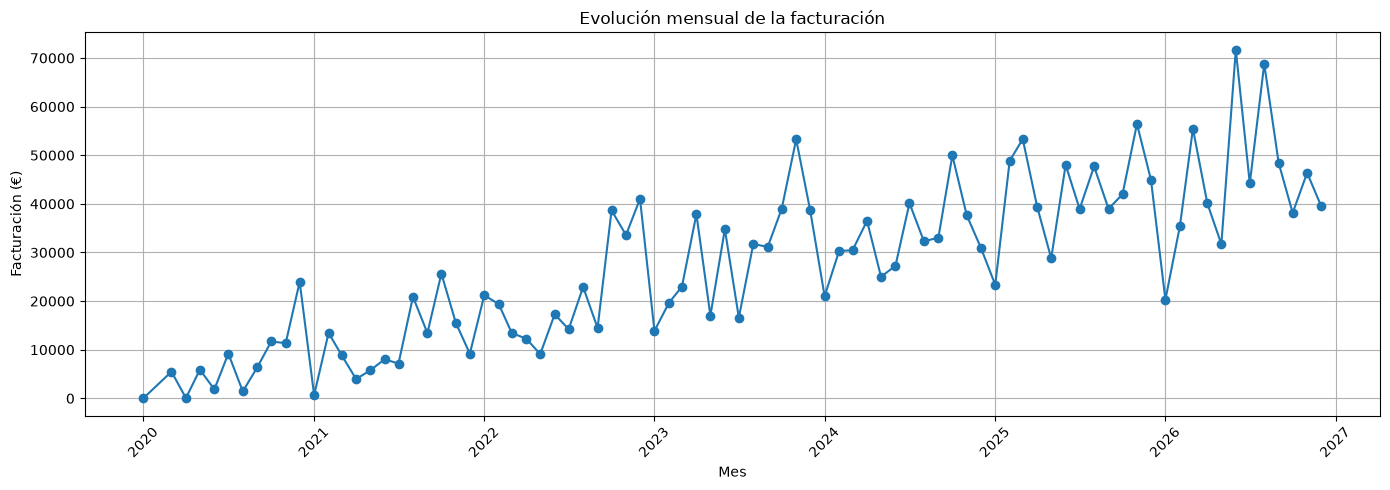

In [380]:
import matplotlib.pyplot as plt

plt.figure(figsize=(14, 5))

plt.plot(
    monthly_performance_df["month"],
    monthly_performance_df["revenue"],
    marker="o"
)

plt.title("Evolución mensual de la facturación")
plt.xlabel("Mes")
plt.ylabel("Facturación (€)")
plt.xticks(rotation=45)
plt.grid(True)
plt.tight_layout()
plt.show()

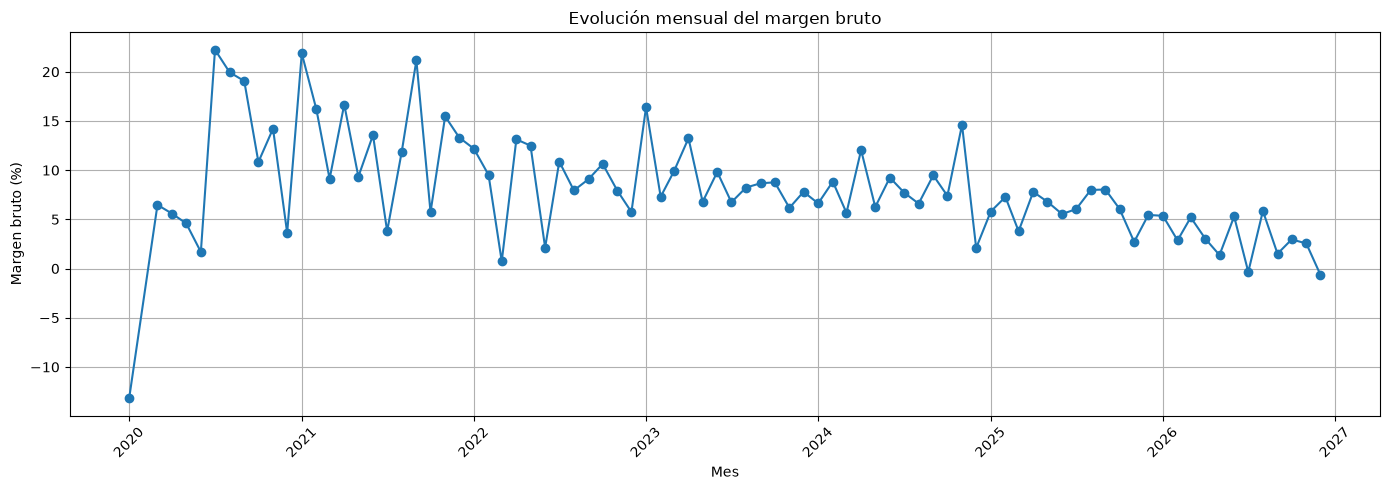

In [381]:
plt.figure(figsize=(14, 5))

plt.plot(
    monthly_performance_df["month"],
    monthly_performance_df["gross_margin"],
    marker="o"
)

plt.title("Evolución mensual del margen bruto")
plt.xlabel("Mes")
plt.ylabel("Margen bruto (%)")
plt.xticks(rotation=45)
plt.grid(True)
plt.tight_layout()
plt.show()

## Identificación de los meses con menor rentabilidad

Tras observar la evolución mensual, se aprecia un deterioro progresivo del margen bruto a pesar del crecimiento de la facturación.

Para profundizar en este comportamiento, identificaremos los meses con menor rentabilidad y analizaremos sus niveles de facturación, costes y beneficio bruto.

In [382]:
worst_months_df = (
    monthly_performance_df
    .sort_values("gross_margin", ascending=True)
    .head(10)
)

worst_months_df[
    [
        "month",
        "total_sales",
        "revenue",
        "total_cost",
        "gross_profit",
        "gross_margin"
    ]
]

,month,total_sales,revenue,total_cost,gross_profit,gross_margin
0,2020-01-01,1,44.181500,50.00,-5.818500,-13.169539
82,2026-12-01,35,39559.143323,39809.38,-250.236677,-0.632563
77,2026-07-01,50,44208.065338,44360.00,-151.934662,-0.343681
25,2022-03-01,16,13431.586011,13333.34,98.246011,0.731455
75,2026-05-01,39,31710.263439,31275.50,434.763439,1.371050
79,2026-09-01,46,48392.865325,47663.66,729.205325,1.506845
4,2020-06-01,4,1839.056046,1808.00,31.056046,1.688695
58,2024-12-01,30,31008.537345,30360.12,648.417345,2.091093
28,2022-06-01,23,17284.601944,16915.83,368.771944,2.133529
81,2026-11-01,51,46377.938853,45194.24,1183.698853,2.552289


### Conversión de fechas

Convertimos la columna `sale_date` al formato datetime de Pandas para poder realizar operaciones temporales, como extraer el año, el mes o el día de cada operación.

In [383]:
sales_analysis_df["sale_date"] = pd.to_datetime(
    sales_analysis_df["sale_date"]
)

## Análisis de rentabilidad por canal en 2026

Tras identificar varios meses con márgenes especialmente reducidos durante 2026, analizaremos la rentabilidad de cada canal comercial.

El objetivo es determinar si el deterioro de los márgenes está relacionado principalmente con el canal B2B o si afecta también a los canales ONLINE y PHYSICAL_STORE.

In [384]:
channel_2026_df = (
    sales_analysis_df[
        sales_analysis_df["sale_date"].dt.year == 2026
    ]
    .groupby("channel")
    .agg(
        total_sales=("sale_id", "nunique"),
        units_sold=("quantity", "sum"),
        revenue=("revenue", "sum"),
        total_cost=("total_cost", "sum"),
        gross_profit=("gross_profit", "sum")
    )
    .reset_index()
)

channel_2026_df["gross_margin"] = (
    channel_2026_df["gross_profit"]
    / channel_2026_df["revenue"]
    * 100
)

channel_2026_df.sort_values(
    "gross_margin",
    ascending=True
)

,channel,total_sales,units_sold,revenue,total_cost,gross_profit,gross_margin
0,B2B,173,337,163203.791199,172707.52,-9503.728801,-5.823228
2,PHYSICAL_STORE,114,227,124519.802063,116001.80,8518.002063,6.840681
1,ONLINE,218,455,252356.325173,234274.48,18081.845173,7.165204


## Impacto de los descuentos en la rentabilidad B2B durante 2026

Tras identificar que el canal B2B presenta un margen bruto negativo, analizaremos el impacto de los descuentos comerciales sobre su rentabilidad.

Realizaremos una simulación sin descuentos, manteniendo constantes las cantidades vendidas y los costes, para estimar cómo habría cambiado el beneficio bruto.

In [385]:
b2b_2026_df = sales_analysis_df[
    (sales_analysis_df["sale_date"].dt.year == 2026) &
    (sales_analysis_df["channel"] == "B2B")
].copy()

b2b_2026_df["gross_revenue"] = (
    b2b_2026_df["quantity"] *
    b2b_2026_df["unit_price"]
)

In [386]:
b2b_discount_impact_df = pd.DataFrame({
    "scenario": ["Actual", "Without discounts"],
    "revenue": [
        b2b_2026_df["revenue"].sum(),
        b2b_2026_df["gross_revenue"].sum()
    ],
    "total_cost": [
        b2b_2026_df["total_cost"].sum(),
        b2b_2026_df["total_cost"].sum()
    ],
    "gross_profit": [
        b2b_2026_df["gross_profit"].sum(),
        b2b_2026_df["gross_revenue"].sum()
        - b2b_2026_df["total_cost"].sum()
    ]
})

b2b_discount_impact_df["gross_margin"] = (
    b2b_discount_impact_df["gross_profit"] /
    b2b_discount_impact_df["revenue"] * 100
)

b2b_discount_impact_df

,scenario,revenue,total_cost,gross_profit,gross_margin
0,Actual,163203.791199,172707.52,-9503.728801,-5.823228
1,Without discounts,194899.320000,172707.52,22191.800000,11.386289


## Rentabilidad por categoría en el canal B2B durante 2026

Una vez identificado el impacto potencial de los descuentos sobre la rentabilidad del canal B2B, analizaremos el comportamiento de cada categoría de producto.

El objetivo es localizar las categorías que generan pérdidas y evaluar dónde debería revisarse la política de descuentos comerciales.

In [387]:
b2b_category_2026_df = (
    b2b_2026_df
    .groupby("category_name")
    .agg(
        total_sales=("sale_id", "nunique"),
        units_sold=("quantity", "sum"),
        revenue=("revenue", "sum"),
        total_cost=("total_cost", "sum"),
        gross_profit=("gross_profit", "sum")
    )
    .reset_index()
)

b2b_category_2026_df["gross_margin"] = (
    b2b_category_2026_df["gross_profit"]
    / b2b_category_2026_df["revenue"] * 100
)

b2b_category_2026_df.sort_values(
    "gross_profit",
    ascending=True
)

,category_name,total_sales,units_sold,revenue,total_cost,gross_profit,gross_margin
8,Servers,11,22,15042.650312,16741.88,-1699.229688,-11.296079
5,Peripherals,21,42,23457.854277,25149.48,-1691.625723,-7.211340
9,Storage,18,36,23477.877770,25000.94,-1523.062230,-6.487223
7,Security,11,14,12134.398856,13559.70,-1425.301144,-11.745956
2,Computers,25,55,19719.687501,20882.52,-1162.832499,-5.896810
1,Components,17,31,14772.900914,15386.76,-613.859086,-4.155305
6,Printing,12,23,10872.730776,11406.88,-534.149224,-4.912742
0,Accessories,15,31,8099.200586,8446.26,-347.059414,-4.285107
4,Networking,16,33,15402.513994,15743.58,-341.066006,-2.214353
3,Monitors,27,50,20223.976213,20389.52,-165.543787,-0.818552


## Simulación del impacto de los descuentos por categoría en B2B

Tras comprobar que todas las categorías del canal B2B presentan pérdidas durante 2026, analizaremos el impacto de los descuentos comerciales individualmente.

Compararemos la rentabilidad real de cada categoría con un escenario hipotético sin descuentos, manteniendo constantes las unidades vendidas y los costes.

In [388]:
b2b_category_impact_df = (
    b2b_2026_df
    .groupby("category_name")
    .agg(
        total_sales=("sale_id", "nunique"),
        units_sold=("quantity", "sum"),
        revenue=("revenue", "sum"),
        total_cost=("total_cost", "sum"),
        gross_profit=("gross_profit", "sum"),
        gross_revenue=("gross_revenue", "sum")
    )
    .reset_index()
)

# Importe de los descuentos aplicados
b2b_category_impact_df["discount_amount"] = (
    b2b_category_impact_df["gross_revenue"]
    - b2b_category_impact_df["revenue"]
)

# Beneficio bruto hipotético sin descuentos
b2b_category_impact_df["profit_without_discount"] = (
    b2b_category_impact_df["gross_revenue"]
    - b2b_category_impact_df["total_cost"]
)

# Margen bruto hipotético sin descuentos
b2b_category_impact_df["margin_without_discount"] = (
    b2b_category_impact_df["profit_without_discount"]
    / b2b_category_impact_df["gross_revenue"]
    * 100
)

b2b_category_impact_df.sort_values(
    "gross_profit",
    ascending=True
)

,category_name,total_sales,units_sold,revenue,total_cost,gross_profit,gross_revenue,discount_amount,profit_without_discount,margin_without_discount
8,Servers,11,22,15042.650312,16741.88,-1699.229688,17886.08,2843.429688,1144.20,6.397154
5,Peripherals,21,42,23457.854277,25149.48,-1691.625723,28155.24,4697.385723,3005.76,10.675668
9,Storage,18,36,23477.877770,25000.94,-1523.062230,27581.45,4103.572230,2580.51,9.355962
7,Security,11,14,12134.398856,13559.70,-1425.301144,14563.27,2428.871144,1003.57,6.891103
2,Computers,25,55,19719.687501,20882.52,-1162.832499,24209.30,4489.612499,3326.78,13.741744
1,Components,17,31,14772.900914,15386.76,-613.859086,17561.13,2788.229086,2174.37,12.381720
6,Printing,12,23,10872.730776,11406.88,-534.149224,12848.02,1975.289224,1441.14,11.216826
0,Accessories,15,31,8099.200586,8446.26,-347.059414,9621.51,1522.309414,1175.25,12.214819
4,Networking,16,33,15402.513994,15743.58,-341.066006,18583.95,3181.436006,2840.37,15.283995
3,Monitors,27,50,20223.976213,20389.52,-165.543787,23889.37,3665.393787,3499.85,14.650240


## Impacto económico de los descuentos en el canal B2B

En este apartado cuantificamos el impacto económico de los descuentos comerciales aplicados al canal B2B.

Comparamos el beneficio bruto actual con el beneficio hipotético que obtendríamos manteniendo constantes las cantidades vendidas y los costes, pero eliminando los descuentos.

El objetivo es dimensionar la pérdida de rentabilidad asociada a la política comercial actual.

In [389]:
b2b_discount_impact = b2b_category_impact_df[
    ["gross_profit", "profit_without_discount", "discount_amount"]
].sum()

b2b_discount_impact

gross_profit               -9503.728801
profit_without_discount    22191.800000
discount_amount            31695.528801
dtype: float64

## Conclusión: impacto de los descuentos en B2B

El análisis muestra que el canal B2B presenta un beneficio bruto negativo total de 9.503,73 €.

En una simulación sin descuentos, manteniendo constantes las unidades vendidas y los costes, el beneficio bruto alcanzaría los 22.191,80 €, lo que supone una mejora hipotética de 31.695,53 €.

Estos resultados evidencian el impacto de descuentos sobre la rentabilidad del canal.

No obstante, eliminar los descuentos podría afectar al volumen de ventas y a la retención de clientes. Por tanto, se debe estudiar la rentabilidad individual de los clientes B2B y evaluar posibles ajustes comerciales antes de modificar la política de precios.

## Análisis de rentabilidad por cliente B2B

En este punto analizamos la rentabilidad individual de los clientes del canal B2B.

El objetivo es identificar qué clientes generan mayor facturación, cuáles aportan mayor beneficio bruto y cuáles presentan una rentabilidad negativa.

También estudiaremos el impacto de los descuentos comerciales sobre la rentabilidad de cada cliente, con el fin de detectar posibles oportunidades de mejora en las condiciones comerciales.

In [390]:
b2b_customer_profitability_df = (
    sales_analysis_df[
        sales_analysis_df["channel"] == "B2B"
    ]
    .assign(
        gross_revenue_line=lambda df: (
            df["quantity"] * df["unit_price"]
        )
    )
    .groupby("customer_id")
    .agg(
        total_sales=("sale_id", "nunique"),
        units_sold=("quantity", "sum"),
        revenue=("revenue", "sum"),
        total_cost=("total_cost", "sum"),
        gross_profit=("gross_profit", "sum"),
        gross_revenue=("gross_revenue_line", "sum")
    )
    .reset_index()
)

In [391]:
b2b_customer_profitability_df.head()

,customer_id,total_sales,units_sold,revenue,total_cost,gross_profit,gross_revenue
0,1,2,4,2720.311828,2823.20,-102.888172,3093.76
1,4,1,2,46.772000,55.40,-8.628000,55.00
2,7,2,5,2305.149101,2118.54,186.609101,2657.17
3,10,8,15,10930.370770,10242.91,687.460770,13247.92
4,13,6,13,4762.528952,4834.31,-71.781048,5579.77


In [392]:
b2b_customer_profitability_df.columns.tolist()

['customer_id',
 'total_sales',
 'units_sold',
 'revenue',
 'total_cost',
 'gross_profit',
 'gross_revenue']

In [393]:
b2b_customer_profitability_df["gross_margin"] = (
    b2b_customer_profitability_df["gross_profit"]
    / b2b_customer_profitability_df["revenue"]
    * 100
)

In [394]:
b2b_customer_profitability_df = (
    b2b_customer_profitability_df
    .sort_values("gross_profit", ascending=False)
    .reset_index(drop=True)
)

b2b_customer_profitability_df

,customer_id,total_sales,units_sold,revenue,total_cost,gross_profit,gross_revenue,gross_margin
0,307,19,37,24749.939088,22655.06,2094.879088,28570.33,8.464179
1,238,5,12,10045.471419,9275.47,770.001419,11530.01,7.665160
2,10,8,15,10930.370770,10242.91,687.460770,13247.92,6.289455
3,160,7,14,9235.219195,8738.69,496.529195,11046.67,5.376474
4,325,4,7,8219.834292,7804.10,415.734292,9684.14,5.057697
...,...,...,...,...,...,...,...,...
108,22,4,7,7017.914259,7680.55,-662.635741,8254.11,-9.442061
109,73,10,22,13852.025961,14620.49,-768.464039,16484.89,-5.547665
110,34,3,7,5206.921170,6094.03,-887.108830,6062.10,-17.037109
111,49,5,9,7729.695237,8802.96,-1073.264763,9405.44,-13.884956


### Rentabilidad negativa por cliente

Identificamos los clientes B2B cuyo beneficio bruto acumulado es negativo.

El objetivo es detectar relaciones comerciales que, pese a generar facturación, están produciendo pérdidas para la empresa y requieren un análisis más detallado.

In [395]:
b2b_unprofitable_customers_df = (
    b2b_customer_profitability_df[
        b2b_customer_profitability_df["gross_profit"] < 0
    ]
    .sort_values("gross_profit", ascending=True)
    .reset_index(drop=True)
)

b2b_unprofitable_customers_df

,customer_id,total_sales,units_sold,revenue,total_cost,gross_profit,gross_revenue,gross_margin
0,295,9,19,14021.095012,15376.93,-1355.834988,16557.74,-9.669965
1,49,5,9,7729.695237,8802.96,-1073.264763,9405.44,-13.884956
2,34,3,7,5206.921170,6094.03,-887.108830,6062.10,-17.037109
3,73,10,22,13852.025961,14620.49,-768.464039,16484.89,-5.547665
4,22,4,7,7017.914259,7680.55,-662.635741,8254.11,-9.442061
...,...,...,...,...,...,...,...,...
68,19,2,6,420.370557,430.35,-9.979443,482.49,-2.373963
69,4,1,2,46.772000,55.40,-8.628000,55.00,-18.446934
70,208,1,3,76.293525,81.75,-5.456475,90.75,-7.151950
71,322,1,3,1779.928062,1785.00,-5.071938,2037.93,-0.284952


In [396]:
b2b_loss_summary_df = pd.DataFrame({
    "metric": [
        "Total B2B customers",
        "Unprofitable customers",
        "Unprofitable customers (%)",
        "Revenue from unprofitable customers",
        "Gross profit from unprofitable customers"
    ],
    "value": [
        len(b2b_customer_profitability_df),
        len(b2b_unprofitable_customers_df),
        (
            len(b2b_unprofitable_customers_df)
            / len(b2b_customer_profitability_df)
        ) * 100,
        b2b_unprofitable_customers_df["revenue"].sum(),
        b2b_unprofitable_customers_df["gross_profit"].sum()
    ]
})

b2b_loss_summary_df

,metric,value
0,Total B2B customers,113.000000
1,Unprofitable customers,73.000000
2,Unprofitable customers (%),64.601770
3,Revenue from unprofitable customers,372369.466193
4,Gross profit from unprofitable customers,-19225.743807


### Top 10 clientes B2B con mayor pérdida bruta

Identificamos los diez clientes que acumulan las mayores pérdidas brutas para evaluar dónde se concentra el impacto económico negativo de la cartera B2B.

In [397]:

b2b_top_loss_customers_df = (
    b2b_unprofitable_customers_df
    .nsmallest(10, "gross_profit")
    .reset_index(drop=True)
)

b2b_top_loss_customers_df[
    [
        "customer_id",
        "total_sales",
        "units_sold",
        "revenue",
        "gross_profit",
        "gross_margin"
    ]
]

,customer_id,total_sales,units_sold,revenue,gross_profit,gross_margin
0,295,9,19,14021.095012,-1355.834988,-9.669965
1,49,5,9,7729.695237,-1073.264763,-13.884956
2,34,3,7,5206.921170,-887.108830,-17.037109
3,73,10,22,13852.025961,-768.464039,-5.547665
4,22,4,7,7017.914259,-662.635741,-9.442061
5,292,3,8,8384.526003,-650.113997,-7.753736
6,199,6,12,5504.820532,-632.029468,-11.481382
7,259,4,8,5227.429968,-626.730032,-11.989257
8,67,4,6,3281.500934,-578.709066,-17.635499
9,352,6,16,5033.724470,-575.915530,-11.441141


### Concentración de pérdidas en los principales clientes

Evaluamos qué proporción de las pérdidas brutas de la cartera B2B se concentra en los diez clientes menos rentables.

Este análisis permite determinar si el problema está concentrado en un grupo reducido de clientes o si afecta de forma generalizada a la cartera comercial.

In [398]:
top_10_loss = b2b_top_loss_customers_df["gross_profit"].sum()

total_b2b_loss = b2b_unprofitable_customers_df["gross_profit"].sum()

b2b_loss_concentration_df = pd.DataFrame({
    "metric": [
        "Top 10 customers gross loss",
        "Total B2B gross loss",
        "Top 10 share of total losses (%)"
    ],
    "value": [
        top_10_loss,
        total_b2b_loss,
        abs(top_10_loss) / abs(total_b2b_loss) * 100
    ]
})

b2b_loss_concentration_df

,metric,value
0,Top 10 customers gross loss,-7810.806454
1,Total B2B gross loss,-19225.743807
2,Top 10 share of total losses (%),40.626810


### Comparación entre clientes B2B rentables y no rentables

Comparamos el comportamiento comercial de los clientes B2B según su rentabilidad acumulada.

Analizamos el número de clientes, volumen de ventas, unidades comercializadas, facturación y beneficio bruto para identificar diferencias entre ambos grupos.

In [399]:
b2b_customer_comparison_df = (
    b2b_customer_profitability_df
    .assign(
        profitability_group=lambda df: np.where(
            df["gross_profit"] < 0,
            "Unprofitable",
            "Profitable"
        )
    )
    .groupby("profitability_group")
    .agg(
        customers=("customer_id", "nunique"),
        total_sales=("total_sales", "sum"),
        units_sold=("units_sold", "sum"),
        revenue=("revenue", "sum"),
        total_cost=("total_cost", "sum"),
        gross_profit=("gross_profit", "sum")
    )
    .reset_index()
)

b2b_customer_comparison_df["gross_margin"] = (
    b2b_customer_comparison_df["gross_profit"]
    / b2b_customer_comparison_df["revenue"]
    * 100
)

b2b_customer_comparison_df

,profitability_group,customers,total_sales,units_sold,revenue,total_cost,gross_profit,gross_margin
0,Profitable,40,296,578,296131.760144,285777.78,10353.980144,3.496410
1,Unprofitable,73,387,775,372369.466193,391595.21,-19225.743807,-5.163083


### Análisis de descuentos según la rentabilidad del cliente

Comparamos las políticas de descuentos aplicadas a los clientes B2B rentables y no rentables.

El objetivo es determinar si los clientes que generan un beneficio bruto negativo reciben descuentos más elevados y evaluar la posible relación entre el nivel de descuentos y la rentabilidad comercial.

In [400]:
b2b_discount_analysis_df = (
    sales_analysis_df[
        sales_analysis_df["channel"] == "B2B"
    ]
    .merge(
        b2b_customer_profitability_df[
            ["customer_id", "gross_profit"]
        ],
        on="customer_id",
        suffixes=("", "_customer")
    )
    .assign(
        profitability_group=lambda df: np.where(
            df["gross_profit_customer"] < 0,
            "Unprofitable",
            "Profitable"
        ),
        gross_revenue=lambda df: (
            df["quantity"] * df["unit_price"]
        ),
        discount_amount=lambda df: (
            df["quantity"]
            * df["unit_price"]
            * df["discount"]
        )
    )
    .groupby("profitability_group")
    .agg(
        customers=("customer_id", "nunique"),
        gross_revenue=("gross_revenue", "sum"),
        discount_amount=("discount_amount", "sum"),
        revenue=("revenue", "sum"),
        total_cost=("total_cost", "sum"),
        gross_profit=("gross_profit", "sum"),
        avg_discount=("discount", "mean")
    )
    .reset_index()
)

b2b_discount_analysis_df["discount_pct"] = (
    b2b_discount_analysis_df["discount_amount"]
    / b2b_discount_analysis_df["gross_revenue"]
    * 100
)

b2b_discount_analysis_df["gross_margin"] = (
    b2b_discount_analysis_df["gross_profit"]
    / b2b_discount_analysis_df["revenue"]
    * 100
)

b2b_discount_analysis_df

,profitability_group,customers,gross_revenue,discount_amount,revenue,total_cost,gross_profit,avg_discount,discount_pct,gross_margin
0,Profitable,40,350216.76,54084.999856,296131.760144,285777.78,10353.980144,0.156704,15.443293,3.496410
1,Unprofitable,73,445143.40,72773.933807,372369.466193,391595.21,-19225.743807,0.162438,16.348425,-5.163083


### Análisis de categorías compradas por clientes B2B no rentables

Analizamos qué categorías de productos concentran la facturación y las pérdidas de los clientes B2B con rentabilidad negativa.

El objetivo es identificar posibles patrones de compra y determinar si determinadas categorías están contribuyendo especialmente a los resultados negativos de este grupo de clientes.

In [401]:
b2b_unprofitable_category_df = (
    sales_analysis_df[
        (sales_analysis_df["channel"] == "B2B")
        & (
            sales_analysis_df["customer_id"].isin(
                b2b_unprofitable_customers_df["customer_id"]
            )
        )
    ]
    .groupby("category_name")
    .agg(
        total_sales=("sale_id", "nunique"),
        customers=("customer_id", "nunique"),
        units_sold=("quantity", "sum"),
        revenue=("revenue", "sum"),
        total_cost=("total_cost", "sum"),
        gross_profit=("gross_profit", "sum")
    )
    .reset_index()
)

b2b_unprofitable_category_df["gross_margin"] = (
    b2b_unprofitable_category_df["gross_profit"]
    / b2b_unprofitable_category_df["revenue"]
    * 100
)

b2b_unprofitable_category_df = (
    b2b_unprofitable_category_df
    .sort_values("gross_profit")
    .reset_index(drop=True)
)

b2b_unprofitable_category_df

,category_name,total_sales,customers,units_sold,revenue,total_cost,gross_profit,gross_margin
0,Storage,41,32,76,52698.737707,57743.36,-5044.622293,-9.572568
1,Peripherals,37,27,81,41927.033373,46264.27,-4337.236627,-10.344726
2,Servers,33,25,69,40735.535208,43412.73,-2677.194792,-6.572136
3,Networking,38,29,77,52828.893669,55017.70,-2188.806331,-4.143199
4,Security,28,24,49,38819.703577,40416.11,-1596.406423,-4.112361
5,Computers,65,41,133,43517.266862,44915.36,-1398.093138,-3.212732
6,Printing,19,16,43,14838.907319,16123.34,-1284.432681,-8.655844
7,Monitors,37,30,74,38513.239345,39379.92,-866.680655,-2.250345
8,Components,61,35,118,33639.234826,34100.27,-461.035174,-1.370528
9,Accessories,28,25,55,14850.914307,14222.15,628.764307,4.233842


### Análisis de pérdidas por categoría de producto en clientes B2B no rentables

Analizamos el beneficio bruto generado por los clientes B2B no rentables en las distintas categorías de productos.

El objetivo es identificar qué categorías contribuyen en mayor medida a las pérdidas y determinar si la rentabilidad negativa se concentra en determinadas categorías o está repartida entre todas ellas.

In [402]:
b2b_unprofitable_category_impact_df = (
    sales_analysis_df[
        (sales_analysis_df["channel"] == "B2B") &
        (sales_analysis_df["customer_id"].isin(
            b2b_unprofitable_customers_df["customer_id"]
        ))
    ]
    .groupby("category_name")
    .agg(
        total_customers=("customer_id", "nunique"),
        total_sales=("sale_id", "nunique"),
        units_sold=("quantity", "sum"),
        revenue=("revenue", "sum"),
        total_cost=("total_cost", "sum"),
        gross_profit=("gross_profit", "sum")
    )
    .reset_index()
    .sort_values("gross_profit")
    .reset_index(drop=True)
)

b2b_unprofitable_category_impact_df

,category_name,total_customers,total_sales,units_sold,revenue,total_cost,gross_profit
0,Storage,32,41,76,52698.737707,57743.36,-5044.622293
1,Peripherals,27,37,81,41927.033373,46264.27,-4337.236627
2,Servers,25,33,69,40735.535208,43412.73,-2677.194792
3,Networking,29,38,77,52828.893669,55017.70,-2188.806331
4,Security,24,28,49,38819.703577,40416.11,-1596.406423
5,Computers,41,65,133,43517.266862,44915.36,-1398.093138
6,Printing,16,19,43,14838.907319,16123.34,-1284.432681
7,Monitors,30,37,74,38513.239345,39379.92,-866.680655
8,Components,35,61,118,33639.234826,34100.27,-461.035174
9,Accessories,25,28,55,14850.914307,14222.15,628.764307


### Concentración de pérdidas por categoría

Calculamos el peso de las pérdidas de cada categoría sobre las pérdidas totales generadas por los clientes B2B no rentables.

El objetivo es identificar las categorías que concentran una mayor parte del impacto económico negativo y establecer prioridades para futuras acciones comerciales.

In [403]:

b2b_category_loss_concentration_df = (
    b2b_unprofitable_category_impact_df.copy()
)

total_losses = abs(
    b2b_category_loss_concentration_df.loc[
        b2b_category_loss_concentration_df["gross_profit"] < 0,
        "gross_profit"
    ].sum()
)

b2b_category_loss_concentration_df["loss_share_pct"] = (
    b2b_category_loss_concentration_df["gross_profit"]
    .clip(upper=0)
    .abs()
    / total_losses
    * 100
)

b2b_category_loss_concentration_df = (
    b2b_category_loss_concentration_df
    .sort_values("loss_share_pct", ascending=False)
    .reset_index(drop=True)
)

b2b_category_loss_concentration_df

,category_name,total_customers,total_sales,units_sold,revenue,total_cost,gross_profit,loss_share_pct
0,Storage,32,41,76,52698.737707,57743.36,-5044.622293,25.407944
1,Peripherals,27,37,81,41927.033373,46264.27,-4337.236627,21.845097
2,Servers,25,33,69,40735.535208,43412.73,-2677.194792,13.484065
3,Networking,29,38,77,52828.893669,55017.70,-2188.806331,11.024228
4,Security,24,28,49,38819.703577,40416.11,-1596.406423,8.040524
5,Computers,41,65,133,43517.266862,44915.36,-1398.093138,7.041691
6,Printing,16,19,43,14838.907319,16123.34,-1284.432681,6.469224
7,Monitors,30,37,74,38513.239345,39379.92,-866.680655,4.365158
8,Components,35,61,118,33639.234826,34100.27,-461.035174,2.322068
9,Accessories,25,28,55,14850.914307,14222.15,628.764307,0.000000


### Evolución mensual de la rentabilidad B2B

Analizamos la evolución mensual de las ventas B2B para identificar cambios en los ingresos, los costes, el beneficio bruto y los descuentos aplicados.

El objetivo es detectar periodos en los que la rentabilidad se deteriora y comprobar si existe una relación entre la evolución de los descuentos y los resultados comerciales.

In [404]:
b2b_monthly_profitability_df = (
    sales_analysis_df[
        sales_analysis_df["channel"] == "B2B"
    ]
    .assign(
        year_month=lambda x: x["sale_date"].dt.to_period("M").astype(str),
        gross_revenue=lambda x: x["quantity"] * x["unit_price"],
        discount_amount=lambda x: (
            x["quantity"] * x["unit_price"] * x["discount"]
        )
    )
    .groupby("year_month")
    .agg(
        total_sales=("sale_id", "nunique"),
        total_customers=("customer_id", "nunique"),
        units_sold=("quantity", "sum"),
        gross_revenue=("gross_revenue", "sum"),
        discount_amount=("discount_amount", "sum"),
        revenue=("revenue", "sum"),
        total_cost=("total_cost", "sum"),
        gross_profit=("gross_profit", "sum"),
        avg_discount=("discount", "mean")
    )
    .reset_index()
)

b2b_monthly_profitability_df

,year_month,total_sales,total_customers,units_sold,gross_revenue,discount_amount,revenue,total_cost,gross_profit,avg_discount
0,2020-01,1,1,2,55.00,10.818500,44.181500,50.00,-5.818500,0.196700
1,2020-03,2,1,4,3862.00,683.477912,3178.522088,3060.00,118.522088,0.157200
2,2020-04,1,1,1,68.97,8.600559,60.369441,57.00,3.369441,0.124700
3,2020-06,1,1,2,76.24,14.104400,62.135600,66.00,-3.864400,0.185000
4,2020-07,1,1,3,82.50,11.739750,70.760250,75.00,-4.239750,0.142300
...,...,...,...,...,...,...,...,...,...,...
76,2026-08,22,22,41,24597.41,4066.543449,20530.866551,21292.48,-761.613449,0.165409
77,2026-09,11,10,19,15596.61,2556.746998,13039.863002,14398.46,-1358.596998,0.148373
78,2026-10,17,13,36,8721.45,1371.482258,7349.967742,7680.66,-330.692258,0.157341
79,2026-11,14,14,27,7435.81,1007.960164,6427.849836,6988.18,-560.330164,0.153414


### Evolución mensual de la rentabilidad B2B

Calculamos indicadores adicionales para analizar la evolución de la rentabilidad de los clientes B2B a lo largo del tiempo.

El objetivo es observar cómo se relacionan los descuentos aplicados, el volumen de ventas y el margen bruto, e identificar posibles periodos de deterioro o mejora de la rentabilidad.

In [405]:

b2b_monthly_profitability_df = b2b_monthly_profitability_df.copy()

b2b_monthly_profitability_df["gross_margin_pct"] = (
    b2b_monthly_profitability_df["gross_profit"]
    / b2b_monthly_profitability_df["revenue"]
) * 100

b2b_monthly_profitability_df["discount_pct"] = (
    b2b_monthly_profitability_df["discount_amount"]
    / b2b_monthly_profitability_df["gross_revenue"]
) * 100

b2b_monthly_profitability_df["avg_ticket"] = (
    b2b_monthly_profitability_df["revenue"]
    / b2b_monthly_profitability_df["total_sales"]
)

b2b_monthly_profitability_df.head(10)

,year_month,total_sales,total_customers,units_sold,gross_revenue,discount_amount,revenue,total_cost,gross_profit,avg_discount,gross_margin_pct,discount_pct,avg_ticket
0,2020-01,1,1,2,55.00,10.818500,44.181500,50.0,-5.818500,0.196700,-13.169539,19.670000,44.181500
1,2020-03,2,1,4,3862.00,683.477912,3178.522088,3060.0,118.522088,0.157200,3.728843,17.697512,1589.261044
2,2020-04,1,1,1,68.97,8.600559,60.369441,57.0,3.369441,0.124700,5.581369,12.470000,60.369441
3,2020-06,1,1,2,76.24,14.104400,62.135600,66.0,-3.864400,0.185000,-6.219301,18.500000,62.135600
4,2020-07,1,1,3,82.50,11.739750,70.760250,75.0,-4.239750,0.142300,-5.991711,14.230000,70.760250
5,2020-08,1,1,3,225.72,48.416940,177.303060,171.0,6.303060,0.214500,3.554964,21.450000,177.303060
6,2020-09,2,2,4,1700.88,246.064932,1454.815068,1252.0,202.815068,0.175100,13.940952,14.466919,727.407534
7,2020-10,7,6,15,6915.18,1007.174616,5908.005384,5655.0,253.005384,0.143986,4.282416,14.564691,844.000769
8,2020-11,9,6,18,7859.10,1363.389102,6495.710898,5938.0,557.710898,0.144078,8.585833,17.347904,721.745655
9,2020-12,10,6,17,10369.50,1967.248238,8402.251762,9017.0,-614.748238,0.172670,-7.316470,18.971486,840.225176


### Relación entre descuentos y margen bruto a lo largo del tiempo

Representamos la evolución mensual del descuento aplicado y del margen bruto para identificar posibles relaciones entre ambas variables.

El objetivo es detectar si los incrementos en los descuentos coinciden con una reducción de la rentabilidad comercial.

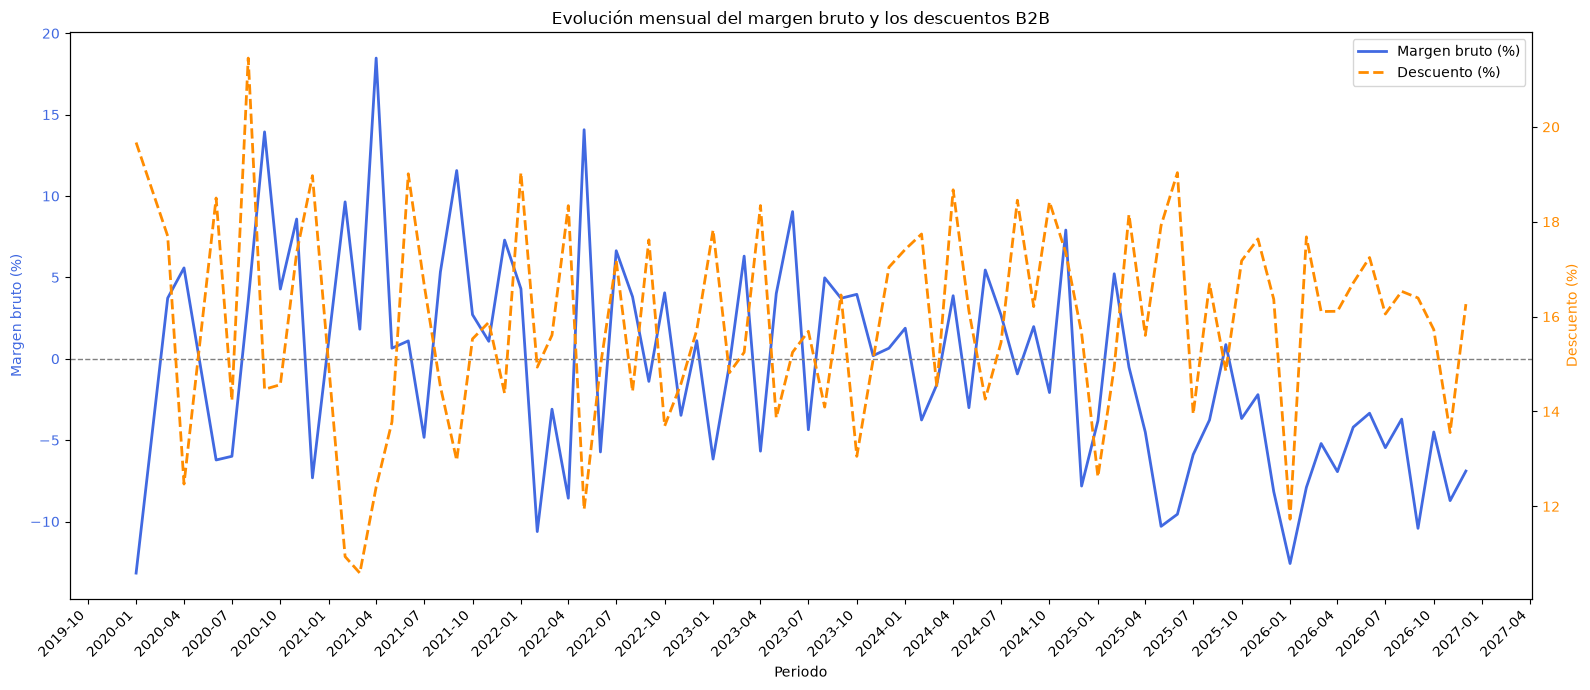

In [406]:
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import pandas as pd

# Convertir el periodo a formato fecha
b2b_monthly_profitability_df["month_date"] = pd.to_datetime(
    b2b_monthly_profitability_df["year_month"]
)

fig, ax1 = plt.subplots(figsize=(16, 7))

# Margen bruto
ax1.plot(
    b2b_monthly_profitability_df["month_date"],
    b2b_monthly_profitability_df["gross_margin_pct"],
    color="royalblue",
    linewidth=2,
    label="Margen bruto (%)"
)

ax1.axhline(0, color="gray", linestyle="--", linewidth=1)

ax1.set_xlabel("Periodo")
ax1.set_ylabel("Margen bruto (%)", color="royalblue")
ax1.tick_params(axis="y", labelcolor="royalblue")

# Descuento
ax2 = ax1.twinx()

ax2.plot(
    b2b_monthly_profitability_df["month_date"],
    b2b_monthly_profitability_df["discount_pct"],
    color="darkorange",
    linewidth=2,
    linestyle="--",
    label="Descuento (%)"
)

ax2.set_ylabel("Descuento (%)", color="darkorange")
ax2.tick_params(axis="y", labelcolor="darkorange")

# Mostrar etiquetas cada tres meses
ax1.xaxis.set_major_locator(mdates.MonthLocator(interval=3))
ax1.xaxis.set_major_formatter(mdates.DateFormatter("%Y-%m"))

plt.setp(ax1.get_xticklabels(), rotation=45, ha="right")

# Leyenda conjunta
lines_1, labels_1 = ax1.get_legend_handles_labels()
lines_2, labels_2 = ax2.get_legend_handles_labels()

ax1.legend(lines_1 + lines_2, labels_1 + labels_2, loc="upper right")

plt.title("Evolución mensual del margen bruto y los descuentos B2B")

fig.tight_layout()
plt.show()

### Evolución del precio de venta y del coste de adquisición B2B

Analizamos la evolución mensual del precio medio de venta y del coste medio de adquisición de los productos vendidos a clientes B2B.

El objetivo es identificar si el deterioro de la rentabilidad está relacionado con un incremento de los costes, una reducción de los precios de venta o una combinación de ambos factores.

In [407]:
sales_analysis_df.columns.tolist()

['sale_id',
 'sale_date',
 'channel',
 'status',
 'customer_id',
 'customer_type',
 'customer_segment',
 'sale_item_id',
 'product_id',
 'product_name',
 'category_id',
 'category_name',
 'quantity',
 'unit_price',
 'discount',
 'effective_unit_price',
 'unit_cost',
 'revenue',
 'total_cost',
 'gross_profit',
 'month']

In [408]:
sales_analysis_df["sale_date"] = pd.to_datetime(sales_analysis_df["sale_date"])

sales_analysis_df["year_month"] = (
    sales_analysis_df["sale_date"]
    .dt.to_period("M")
    .astype(str)
)

In [409]:
b2b_monthly_price_cost_df = (
    sales_analysis_df[
        sales_analysis_df["channel"] == "B2B"
    ]
    .groupby("year_month")
    .agg(
        units_sold=("quantity", "sum"),
        avg_unit_price=("unit_price", "mean"),
        avg_unit_cost=("unit_cost", "mean"),
        avg_effective_price=("effective_unit_price", "mean")
    )
    .reset_index()
)

b2b_monthly_price_cost_df

,year_month,units_sold,avg_unit_price,avg_unit_cost,avg_effective_price
0,2020-01,2,27.500000,25.000000,22.090750
1,2020-03,4,965.500000,765.000000,794.630522
2,2020-04,1,68.970000,57.000000,60.369441
3,2020-06,2,38.120000,33.000000,31.067800
4,2020-07,3,27.500000,25.000000,23.586750
...,...,...,...,...,...
76,2026-08,41,680.763182,590.161818,567.942463
77,2026-09,19,773.727273,704.587273,648.573735
78,2026-10,36,368.468824,317.083529,309.761533
79,2026-11,27,287.207143,270.194286,250.088204


### Evolución mensual de precios y costes

Analizamos la evolución mensual del precio unitario medio, el coste unitario medio y el precio efectivo de venta.

El objetivo es identificar periodos en los que los descuentos reducen el precio de venta hasta comprometer la rentabilidad de las operaciones comerciales.

In [410]:
b2b_monthly_price_cost_df["unit_profit"] = (
    b2b_monthly_price_cost_df["avg_effective_price"]
    - b2b_monthly_price_cost_df["avg_unit_cost"]
)

b2b_monthly_price_cost_df["unit_margin_pct"] = (
    b2b_monthly_price_cost_df["unit_profit"]
    / b2b_monthly_price_cost_df["avg_effective_price"]
    * 100
)

b2b_monthly_price_cost_df.head()

,year_month,units_sold,avg_unit_price,avg_unit_cost,avg_effective_price,unit_profit,unit_margin_pct
0,2020-01,2,27.50,25.0,22.090750,-2.909250,-13.169539
1,2020-03,4,965.50,765.0,794.630522,29.630522,3.728843
2,2020-04,1,68.97,57.0,60.369441,3.369441,5.581369
3,2020-06,2,38.12,33.0,31.067800,-1.932200,-6.219301
4,2020-07,3,27.50,25.0,23.586750,-1.413250,-5.991711


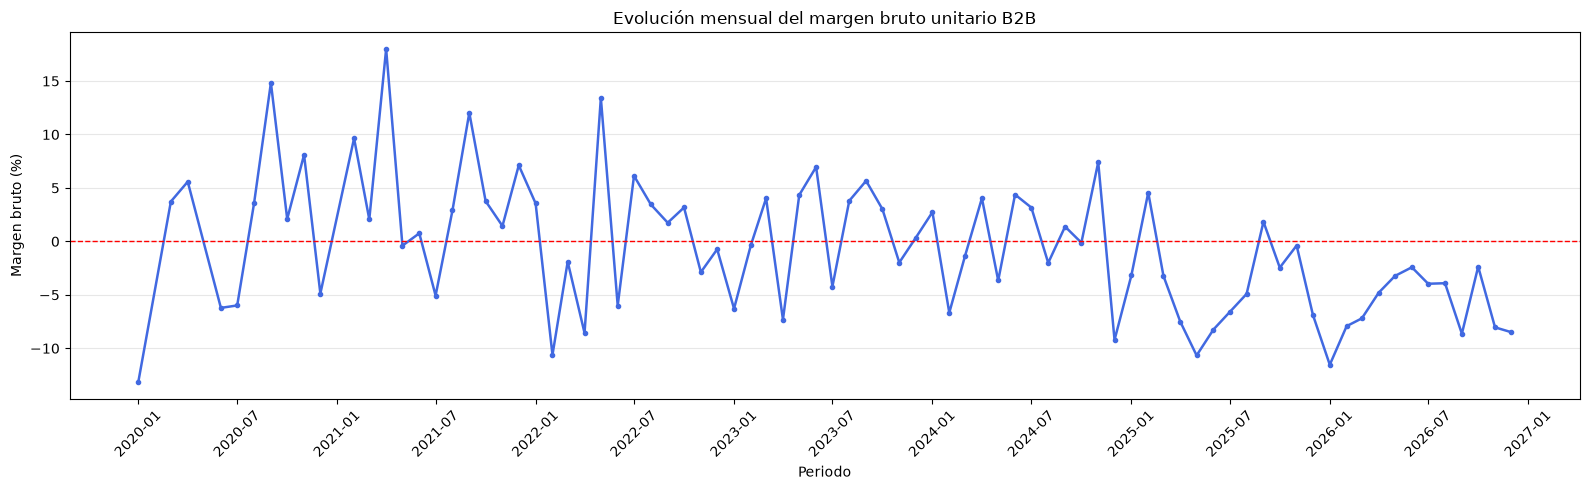

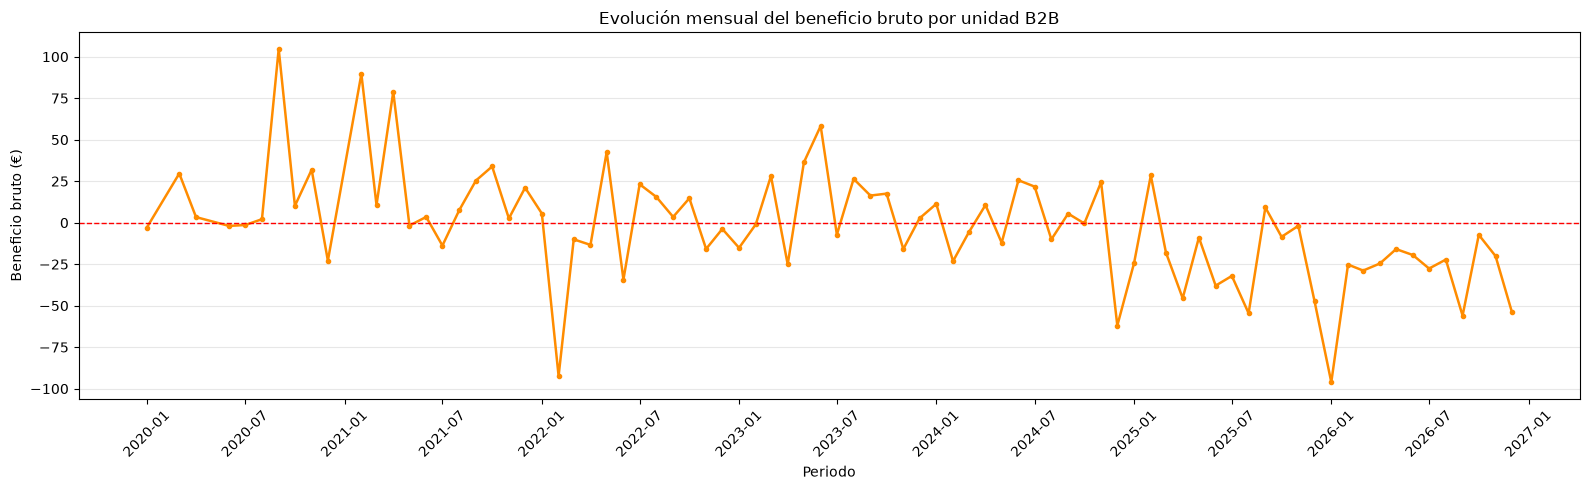

In [411]:
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import pandas as pd

# Preparar fechas para el eje X
plot_df = b2b_monthly_price_cost_df.copy()

plot_df["year_month"] = pd.to_datetime(
    plot_df["year_month"]
)

# Gráfico 1: Margen bruto unitario
fig, ax = plt.subplots(figsize=(16, 5))

ax.plot(
    plot_df["year_month"],
    plot_df["unit_margin_pct"],
    color="royalblue",
    linewidth=1.8,
    marker="o",
    markersize=3
)

ax.axhline(0, color="red", linestyle="--", linewidth=1)

ax.set_title("Evolución mensual del margen bruto unitario B2B")
ax.set_ylabel("Margen bruto (%)")
ax.set_xlabel("Periodo")

ax.xaxis.set_major_locator(mdates.MonthLocator(interval=6))
ax.xaxis.set_major_formatter(mdates.DateFormatter("%Y-%m"))

plt.xticks(rotation=45)
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()


# Gráfico 2: Beneficio bruto por unidad
fig, ax = plt.subplots(figsize=(16, 5))

ax.plot(
    plot_df["year_month"],
    plot_df["unit_profit"],
    color="darkorange",
    linewidth=1.8,
    marker="o",
    markersize=3
)

ax.axhline(0, color="red", linestyle="--", linewidth=1)

ax.set_title("Evolución mensual del beneficio bruto por unidad B2B")
ax.set_ylabel("Beneficio bruto (€)")
ax.set_xlabel("Periodo")

ax.xaxis.set_major_locator(mdates.MonthLocator(interval=6))
ax.xaxis.set_major_formatter(mdates.DateFormatter("%Y-%m"))

plt.xticks(rotation=45)
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

### Identificación de los meses con menor rentabilidad unitaria

Analizamos los meses con menor margen bruto unitario para identificar los periodos más problemáticos.

También tendremos en cuenta el volumen de unidades vendidas, ya que los resultados de meses con poca actividad comercial pueden presentar una mayor variabilidad.

In [412]:
b2b_worst_months_df = (
    b2b_monthly_price_cost_df
    .sort_values("unit_margin_pct")
    .head(15)
    .reset_index(drop=True)
)

b2b_worst_months_df[
    [
        "year_month",
        "units_sold",
        "avg_unit_price",
        "avg_unit_cost",
        "avg_effective_price",
        "unit_profit",
        "unit_margin_pct"
    ]
]

,year_month,units_sold,avg_unit_price,avg_unit_cost,avg_effective_price,unit_profit,unit_margin_pct
0,2020-01,2,27.500000,25.000000,22.090750,-2.909250,-13.169539
1,2026-01,4,942.630000,928.873333,832.783184,-96.090150,-11.538435
2,2025-05,14,101.772500,92.650000,83.719411,-8.930589,-10.667286
3,2022-02,6,1022.810000,962.445000,870.060698,-92.384302,-10.618144
4,2024-12,18,797.323750,734.322500,672.339829,-61.982671,-9.218950
5,2026-09,19,773.727273,704.587273,648.573735,-56.013538,-8.636418
6,2022-04,6,191.253333,169.560000,156.179657,-13.380343,-8.567276
7,2026-12,30,754.458000,683.636000,630.102527,-53.533473,-8.495994
8,2025-06,14,568.597500,498.130000,460.200860,-37.929140,-8.241866
9,2026-11,27,287.207143,270.194286,250.088204,-20.106081,-8.039596


### Análisis de productos con pérdidas en los meses críticos

Identificamos los productos que generan pérdidas en los periodos con menor rentabilidad unitaria.

El objetivo es determinar si las pérdidas se concentran en referencias concretas o si afectan de forma generalizada al catálogo B2B.

In [413]:
critical_months = pd.to_datetime([
    "2026-01-01",
    "2022-02-01",
    "2024-12-01",
    "2026-09-01",
    "2025-05-01",
    "2025-06-01"
])

b2b_critical_products_df = (
    sales_analysis_df[
        (sales_analysis_df["channel"] == "B2B") &
        (sales_analysis_df["month"].isin(critical_months))
    ]
    .groupby(
        ["month", "product_name", "category_name"],
        as_index=False
    )
    .agg(
        units_sold=("quantity", "sum"),
        revenue=("revenue", "sum"),
        total_cost=("total_cost", "sum"),
        gross_profit=("gross_profit", "sum")
    )
)

b2b_critical_products_df["gross_margin_pct"] = (
    b2b_critical_products_df["gross_profit"] /
    b2b_critical_products_df["revenue"] * 100
)

b2b_critical_products_df = (
    b2b_critical_products_df[
        b2b_critical_products_df["gross_profit"] < 0
    ]
    .sort_values("gross_profit")
    .reset_index(drop=True)
)

b2b_critical_products_df.head(20)

,month,product_name,category_name,units_sold,revenue,total_cost,gross_profit,gross_margin_pct
0,2024-12-01,Lenovo Storage Model 15,Storage,4,5944.852980,6830.80,-885.947020,-14.902757
1,2025-06-01,HP Peripherals Model 94,Peripherals,3,3917.832138,4502.79,-584.957862,-14.930651
2,2022-02-01,HP Peripherals Model 64,Peripherals,3,5117.920500,5672.10,-554.179500,-10.828216
3,2026-09-01,Western Digital Security Model 30,Security,3,4023.628857,4577.16,-553.531143,-13.757013
4,2026-01-01,Lenovo Storage Model 15,Storage,2,3089.304900,3530.08,-440.775100,-14.267776
5,2026-09-01,TP-Link Servers Model 29,Servers,2,2187.784060,2608.24,-420.455940,-19.218347
6,2025-06-01,HP Peripherals Model 44,Peripherals,3,2961.436311,3247.11,-285.673689,-9.646457
7,2026-09-01,LG Networking Model 46,Networking,2,2816.320088,3051.44,-235.119912,-8.348480
8,2026-09-01,Western Digital Security Model 10,Security,2,1351.380635,1491.36,-139.979365,-10.358249
9,2024-12-01,TP-Link Servers Model 109,Servers,3,3675.672117,3785.22,-109.547883,-2.980350


### Concentración de pérdidas en productos durante los meses críticos

Calculamos el peso de las pérdidas generadas por cada producto dentro del conjunto de pérdidas de los meses analizados.

El objetivo es identificar qué referencias concentran una mayor parte del impacto económico negativo y establecer prioridades de actuación comercial.

In [414]:
b2b_critical_loss_total = (
    b2b_critical_products_df["gross_profit"].sum()
)

b2b_critical_products_df["loss_share_pct"] = (
    abs(b2b_critical_products_df["gross_profit"]) /
    abs(b2b_critical_loss_total) * 100
)

b2b_critical_products_df = (
    b2b_critical_products_df
    .sort_values("gross_profit")
    .reset_index(drop=True)
)

b2b_critical_products_df[
    [
        "month",
        "product_name",
        "category_name",
        "units_sold",
        "gross_profit",
        "gross_margin_pct",
        "loss_share_pct"
    ]
].head(15)

,month,product_name,category_name,units_sold,gross_profit,gross_margin_pct,loss_share_pct
0,2024-12-01,Lenovo Storage Model 15,Storage,4,-885.947020,-14.902757,19.535688
1,2025-06-01,HP Peripherals Model 94,Peripherals,3,-584.957862,-14.930651,12.898688
2,2022-02-01,HP Peripherals Model 64,Peripherals,3,-554.179500,-10.828216,12.220006
3,2026-09-01,Western Digital Security Model 30,Security,3,-553.531143,-13.757013,12.205709
4,2026-01-01,Lenovo Storage Model 15,Storage,2,-440.775100,-14.267776,9.719368
5,2026-09-01,TP-Link Servers Model 29,Servers,2,-420.455940,-19.218347,9.271318
6,2025-06-01,HP Peripherals Model 44,Peripherals,3,-285.673689,-9.646457,6.299284
7,2026-09-01,LG Networking Model 46,Networking,2,-235.119912,-8.348480,5.184542
8,2026-09-01,Western Digital Security Model 10,Security,2,-139.979365,-10.358249,3.086633
9,2024-12-01,TP-Link Servers Model 109,Servers,3,-109.547883,-2.980350,2.415600


## Ranking de rentabilidad por producto B2B

Analizamos la rentabilidad acumulada de los productos vendidos a través del canal B2B para identificar aquellos que generan mayores pérdidas y detectar posibles problemas estructurales de precios y costes.

In [415]:
b2b_product_profitability_df = (
    sales_analysis_df[
        sales_analysis_df["channel"] == "B2B"
    ]
    .groupby(["product_id", "product_name", "category_name"])
    .agg(
        total_sales=("sale_id", "nunique"),
        units_sold=("quantity", "sum"),
        revenue=("revenue", "sum"),
        total_cost=("total_cost", "sum"),
        gross_profit=("gross_profit", "sum")
    )
    .reset_index()
)

b2b_product_profitability_df["gross_margin_pct"] = (
    b2b_product_profitability_df["gross_profit"]
    / b2b_product_profitability_df["revenue"] * 100
)

b2b_top_loss_products_df = (
    b2b_product_profitability_df[
        b2b_product_profitability_df["gross_profit"] < 0
    ]
    .sort_values("gross_profit")
    .head(10)
    .reset_index(drop=True)
)

b2b_top_loss_products_df

,product_id,product_name,category_name,total_sales,units_sold,revenue,total_cost,gross_profit,gross_margin_pct
0,15,Lenovo Storage Model 15,Storage,14,24,36014.145750,40927.37,-4913.224250,-13.642484
1,64,HP Peripherals Model 64,Peripherals,5,13,21600.499250,24809.05,-3208.550750,-14.854058
2,16,LG Networking Model 16,Networking,13,22,39647.536496,42186.70,-2539.163504,-6.404341
3,8,Samsung Printing Model 8,Printing,13,29,10986.369570,13046.28,-2059.910430,-18.749692
4,43,Dell Monitors Model 43,Monitors,6,13,9883.038000,11541.75,-1658.712000,-16.783422
5,30,Western Digital Security Model 30,Security,4,8,10890.787511,12106.60,-1215.812489,-11.163678
6,94,HP Peripherals Model 94,Peripherals,3,7,9408.528756,10605.67,-1197.141244,-12.724000
7,9,TP-Link Servers Model 9,Servers,13,26,13675.175568,14754.61,-1079.434432,-7.893386
8,31,Acer Computers Model 31,Computers,5,7,11141.701659,12125.91,-984.208341,-8.833555
9,79,TP-Link Servers Model 79,Servers,3,6,9380.045171,10274.84,-894.794829,-9.539345


# Conclusiones del análisis comercial

El análisis del rendimiento comercial de Complex Solutions S.L. ha permitido identificar varios aspectos relevantes sobre la rentabilidad del negocio.

### 1. Impacto de los descuentos

Los descuentos comerciales representan uno de los principales problemas de rentabilidad detectados. Se han identificado operaciones en las que el precio efectivo de venta queda por debajo del coste del producto, generando pérdidas.

La simulación realizada sobre determinadas operaciones muestra que, manteniendo constantes las cantidades vendidas y los costes, eliminar esos descuentos habría supuesto una mejora potencial del beneficio bruto de 36.870,86 €.

### 2. Productos deficitarios

Se han identificado productos que generan pérdidas, tanto en operaciones concretas como en su rentabilidad acumulada. Estos resultados apuntan a la necesidad de revisar determinadas políticas de precios, descuentos y costes de adquisición.

### 3. Clientes B2B

El análisis de clientes permite detectar cuentas comerciales cuya actividad genera un resultado negativo. Esta información puede ayudar a revisar las condiciones comerciales y la rentabilidad de las relaciones con determinados clientes.

### 4. Evolución de la rentabilidad

La evolución temporal muestra fluctuaciones importantes en los márgenes comerciales. Especialmente en el canal B2B, se observan periodos con rentabilidades negativas que merecen atención.

### Recomendaciones empresariales

A partir de los resultados obtenidos, se proponen las siguientes líneas de actuación:

- Revisar las políticas de descuentos y establecer límites comerciales que eviten vender sistemáticamente por debajo del coste.
- Analizar individualmente los productos con pérdidas acumuladas.
- Revisar las condiciones comerciales de los clientes B2B deficitarios.
- Establecer un seguimiento periódico de los márgenes y beneficios por canal, cliente y producto.

El objetivo es mejorar la rentabilidad comercial sin comprometer innecesariamente el volumen de ventas ni las relaciones con los clientes.